# Adversarial Search: Playing "Mean" Connect 4


## Instructions

Total Points: Undegraduates 10, graduate students 11

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play "Mean" Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

> **The mean part:** This game has an additional rule. Every time it is a player's turn, the player can decide to instead of playing a new disk, take a bottom row disk of the opponent and place it in any column. All disks above the removed disk will fall down one position. Note that a player can only move an _opponent's disc_ that is in the _bottom row_ of the board.

Note that normal [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

## Task 1: Defining the Search Problem [1 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

How big is the state space? Give an estimate and explain it.

How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [1]:
import math

def estimate_dots_and_boxes(R, C):
    B = (R - 1) * (C - 1)
    E = R * (C - 1) + (R - 1) * C
    line_states = 2 ** E
    full_states_upper = (2 ** E) * (3 ** B)
    game_tree_leaves = math.factorial(E)
    return B, E, line_states, full_states_upper, game_tree_leaves

for R, C in [(2, 2), (2, 3), (3, 3), (3, 4), (4, 4)]:
    B, E, ls, fs, gt = estimate_dots_and_boxes(R, C)
    print(f"Chấm {R}x{C} ({B} ô, {E} cạnh): 2^E = {ls:.2e} | State Space <= {fs:.2e} | Cây trò chơi (E!) = {gt:.2e}")

Chấm 2x2 (1 ô, 4 cạnh): 2^E = 1.60e+01 | State Space <= 4.80e+01 | Cây trò chơi (E!) = 2.40e+01
Chấm 2x3 (2 ô, 7 cạnh): 2^E = 1.28e+02 | State Space <= 1.15e+03 | Cây trò chơi (E!) = 5.04e+03
Chấm 3x3 (4 ô, 12 cạnh): 2^E = 4.10e+03 | State Space <= 3.32e+05 | Cây trò chơi (E!) = 4.79e+08
Chấm 3x4 (6 ô, 17 cạnh): 2^E = 1.31e+05 | State Space <= 9.56e+07 | Cây trò chơi (E!) = 3.56e+14
Chấm 4x4 (9 ô, 24 cạnh): 2^E = 1.68e+07 | State Space <= 3.30e+11 | Cây trò chơi (E!) = 6.20e+23


## Task 2: Game Environment and Random Agent [3 point]

You can use a numpy character array as the board. Note that the following function can create boards of different sizes.

In [2]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


Instead of colors (red and yellow), you can use 1 and -1 to represent the players Max and Min. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position and player is the player (1, -1) whose next move it is and who the agent should play.

Visualization code by Randolph Rankin:

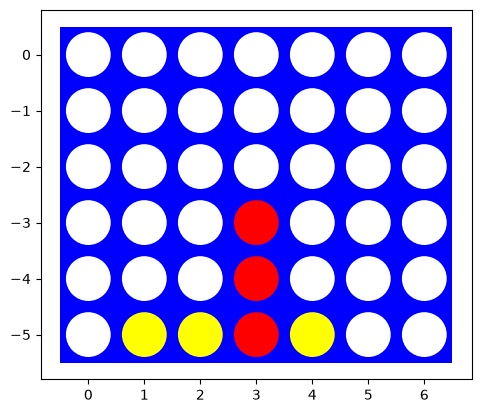

In [3]:
import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]

visualize(board)

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

Make sure that all these functions work with boards of different sizes (number of columns and rows).

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on bt yhe environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [4]:
import matplotlib.pyplot as plt
import numpy as np

def empty_dots_board(size=(4, 4)):
    return {
        'size': size,
        'lines': dict(),
        'boxes': dict()
    }

def copy_dots_board(board):
    return {
        'size': board['size'],
        'lines': board['lines'].copy(),
        'boxes': board['boxes'].copy()
    }

def draw_line(board, orientation, row, col):
    R, C = board['size']
    if orientation not in ['h', 'v'] or row < 0 or col < 0:
        return False
    if orientation == 'h' and (row >= R or col >= C - 1):
        return False
    if orientation == 'v' and (row >= R - 1 or col >= C):
        return False
    if (orientation, row, col) in board['lines']:
        return False
    board['lines'][(orientation, row, col)] = True
    return True

def actions(board):
    """Trả về tất cả các cạnh ('h' hoặc 'v', r, c) chưa được vẽ."""
    R, C = board['size']
    acts = []
    for r in range(R):
        for c in range(C - 1):
            if ('h', r, c) not in board['lines']:
                acts.append(('h', r, c))
    for r in range(R - 1):
        for c in range(C):
            if ('v', r, c) not in board['lines']:
                acts.append(('v', r, c))
    return acts

def is_box_complete(board, r, c):
    lines = board['lines']
    return (('h', r, c) in lines and ('h', r + 1, c) in lines and
            ('v', r, c) in lines and ('v', r, c + 1) in lines)

def result(board, player, action):
    """Thực hiện vẽ cạnh 'action' cho 'player' và cập nhật các ô vuông mới đóng."""
    if action in board['lines']:
        raise ValueError(f"Cạnh {action} đã tồn tại!")
    new_board = copy_dots_board(board)
    ori, r, c = action
    new_board['lines'][action] = True
    R, C = new_board['size']

    # Chỉ kiểm tra tối đa 2 ô vuông liền kề với cạnh vừa vẽ để tối ưu tốc độ
    candidate_boxes = []
    if ori == 'h':
        if r > 0: candidate_boxes.append((r - 1, c))
        if r < R - 1: candidate_boxes.append((r, c))
    else:
        if c > 0: candidate_boxes.append((r, c - 1))
        if c < C - 1: candidate_boxes.append((r, c))

    for br, bc in candidate_boxes:
        if (br, bc) not in new_board['boxes'] and is_box_complete(new_board, br, bc):
            new_board['boxes'][(br, bc)] = player
    return new_board

def terminal(board):
    R, C = board['size']
    return len(board['boxes']) == (R - 1) * (C - 1)

def utility(board, player=1):
    if not terminal(board):
        return None
    p_boxes = sum(1 for owner in board['boxes'].values() if owner == player)
    o_boxes = sum(1 for owner in board['boxes'].values() if owner == -player)
    if p_boxes > o_boxes: return 1
    if p_boxes < o_boxes: return -1
    return 0

def show_dots_board_text(board):
    """Hiển thị bàn cờ Dots and Boxes bằng văn bản trực quan."""
    R, C = board['size']
    for r in range(R):
        # Vẽ hàng chấm và cạnh ngang
        row_str = ""
        for c in range(C - 1):
            row_str += "o" + ("---" if ('h', r, c) in board['lines'] else "   ")
        row_str += "o"
        print(row_str)
        # Vẽ hàng cạnh dọc và ký hiệu chủ sở hữu ô vuông
        if r < R - 1:
            box_str = ""
            for c in range(C - 1):
                v_line = "|" if ('v', r, c) in board['lines'] else " "
                owner = board['boxes'].get((r, c), 0)
                sym = " +1" if owner == 1 else (" -1" if owner == -1 else "   ")
                box_str += v_line + sym
            box_str += "|" if ('v', r, C - 1) in board['lines'] else " "
            print(box_str)

def visualize_dots_board(board):
    """Hiển thị đồ họa bàn cờ Dots and Boxes bằng Matplotlib."""
    R, C = board['size']
    fig, ax = plt.subplots(figsize=(C * 1.2, R * 1.2))
    # Vẽ các đoạn thẳng đã nối
    for (ori, r, c) in board['lines']:
        if ori == 'h':
            ax.plot([c, c + 1], [-r, -r], color='black', lw=3)
        else:
            ax.plot([c, c], [-r, -(r + 1)], color='black', lw=3)
    # Vẽ các chấm tròn
    for r in range(R):
        for c in range(C):
            ax.plot(c, -r, 'o', color='navy', markersize=8)
    # Vẽ nhãn chủ sở hữu ô vuông
    for (br, bc), owner in board['boxes'].items():
        color = 'red' if owner == 1 else 'goldenrod'
        label = '+1' if owner == 1 else '-1'
        ax.text(bc + 0.5, -(br + 0.5), label, fontsize=14, weight='bold',
                color=color, ha='center', va='center')
    ax.set_xlim(-0.3, C - 0.7)
    ax.set_ylim(-(R - 0.7), 0.3)
    ax.set_aspect('equal')
    ax.axis('off')
    plt.show()

def random_dots_player(board, player=1):
    acts = actions(board)
    return acts[np.random.randint(len(acts))]

def play_dots_and_boxes(agent1, agent2, N=1000, size=(3, 3)):
    """Môi trường thi đấu Dots and Boxes có áp dụng luật đi thêm lượt khi đóng được ô."""
    results = {1: 0, -1: 0, 0: 0}
    for _ in range(N):
        board = empty_dots_board(size)
        curr_player = 1
        while not terminal(board):
            prev_boxes = len(board['boxes'])
            agent = agent1 if curr_player == 1 else agent2
            move = agent(board, player=curr_player)
            board = result(board, curr_player, move)
            new_boxes = len(board['boxes'])
            # Chỉ đổi lượt nếu người chơi KHÔNG đóng được ô vuông nào mới
            if new_boxes == prev_boxes:
                curr_player = -curr_player
        u = utility(board, player=1)
        results[u] += 1
    return results

np.random.seed(42)
print("Random vs Random (1000 ván, lưới 3x3 chấm = 4 ô):", play_dots_and_boxes(random_dots_player, random_dots_player, N=1000, size=(3, 3)))
print("Random vs Random (1000 ván, lưới 4x4 chấm = 9 ô):", play_dots_and_boxes(random_dots_player, random_dots_player, N=1000, size=(4, 4)))

Random vs Random (1000 ván, lưới 3x3 chấm = 4 ô): {1: 400, -1: 432, 0: 168}
Random vs Random (1000 ván, lưới 4x4 chấm = 9 ô): {1: 479, -1: 521, 0: 0}


## Task 3: Minimax Search with Alpha-Beta Pruning [3 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for a $6 \times 7$ board is large. You can experiment with smaller boards (the smallest is $4 \times 4$) and/or changing the winning rule to connect 3 instead of 4.

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [5]:
def box_edge_count(board, br, bc):
    lines = board['lines']
    return sum([
        ('h', br, bc) in lines,
        ('h', br + 1, bc) in lines,
        ('v', br, bc) in lines,
        ('v', br, bc + 1) in lines
    ])

def ordered_dots_actions(board, use_ordering=True):
    acts = actions(board)
    if not use_ordering:
        return acts
    R, C = board['size']
    def action_priority(act):
        ori, r, c = act
        adj = []
        if ori == 'h':
            if r > 0: adj.append((r - 1, c))
            if r < R - 1: adj.append((r, c))
        else:
            if c > 0: adj.append((r, c - 1))
            if c < C - 1: adj.append((r, c))
        counts = [box_edge_count(board, br, bc) for br, bc in adj]
        if 3 in counts:
            return 0  # Đóng ô ăn điểm ngay
        if 2 in counts:
            return 2  # Nguy hiểm: tạo cạnh thứ 3 cho ô vuông
        return 1      # Nước đi an toàn (ô mới có 0 hoặc 1 cạnh)
    return sorted(acts, key=action_priority)

class DotsAlphaBetaAgent:
    def __init__(self, use_move_ordering=True):
        self.use_move_ordering = use_move_ordering
        self.node_count = 0

    def search(self, board, player=1):
        self.node_count = 0
        val, move = self._ab_search(board, player, player, -math.inf, math.inf)
        return {"move": move, "value": val, "nodes": self.node_count}

    def _ab_search(self, state, root_player, curr_player, alpha, beta):
        self.node_count += 1
        u = utility(state, root_player)
        if u is not None:
            return u, None

        prev_boxes = len(state['boxes'])
        acts = ordered_dots_actions(state, self.use_move_ordering)

        if curr_player == root_player:  # Nút MAX
            v, best_move = -math.inf, None
            for a in acts:
                next_state = result(state, curr_player, a)
                next_player = curr_player if len(next_state['boxes']) > prev_boxes else -curr_player
                v2, _ = self._ab_search(next_state, root_player, next_player, alpha, beta)
                if v2 > v:
                    v, best_move = v2, a
                    alpha = max(alpha, v)
                if v >= beta:
                    return v, best_move
            return v, best_move
        else:                           # Nút MIN
            v, best_move = math.inf, None
            for a in acts:
                next_state = result(state, curr_player, a)
                next_player = curr_player if len(next_state['boxes']) > prev_boxes else -curr_player
                v2, _ = self._ab_search(next_state, root_player, next_player, alpha, beta)
                if v2 < v:
                    v, best_move = v2, a
                    beta = min(beta, v)
                if v <= alpha:
                    return v, best_move
            return v, best_move

    def __call__(self, board, player=1):
        return self.search(board, player)["move"]

## Task 4: Heuristic Alpha-Beta Tree Search [3 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

Experiment with the same manually created boards as above to check if the agent spots winning opportunities.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

## Tournament task [+ 1 to 5 bonus point will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [1 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+1 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

### Best First Move

How would you determine what the best first move for a standard board ($6 \times 7$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [6]:
def eval_dots(board, root_player=1, curr_player=1):
    u = utility(board, root_player)
    if u is not None:
        return float(u), True

    R, C = board['size']
    total_boxes = (R - 1) * (C - 1)
    p_boxes = sum(1 for v in board['boxes'].values() if v == root_player)
    o_boxes = sum(1 for v in board['boxes'].values() if v == -root_player)
    score = (p_boxes - o_boxes) / total_boxes

    # Đếm số ô có 3 cạnh (sẵn sàng bị ăn bởi người đang tới lượt curr_player)
    c3 = 0
    for br in range(R - 1):
        for bc in range(C - 1):
            if (br, bc) not in board['boxes'] and box_edge_count(board, br, bc) == 3:
                c3 += 1
    turn_sign = 1.0 if curr_player == root_player else -1.0
    score += turn_sign * 0.5 * (c3 / total_boxes)
    return float(np.clip(score, -0.99, 0.99)), False

class HeuristicDotsAgent:
    def __init__(self, cutoff=4):
        self.cutoff = cutoff
        self.node_count = 0

    def search(self, board, player=1):
        self.node_count = 0
        val, move = self._ab_cutoff(board, player, player, -math.inf, math.inf, 0)
        return {"move": move, "value": round(val, 4), "nodes": self.node_count}

    def _ab_cutoff(self, state, root_player, curr_player, alpha, beta, depth):
        self.node_count += 1
        v_eval, is_term = eval_dots(state, root_player, curr_player)
        if is_term or (self.cutoff is not None and depth >= self.cutoff):
            return v_eval, None

        prev_boxes = len(state['boxes'])
        acts = ordered_dots_actions(state, use_ordering=True)
        if curr_player == root_player:
            v, best_move = -math.inf, None
            for a in acts:
                nxt = result(state, curr_player, a)
                nxt_p = curr_player if len(nxt['boxes']) > prev_boxes else -curr_player
                # Nếu ăn được ô và đi tiếp, giữ nguyên hoặc tăng nhẹ depth để theo dõi hết chuỗi ăn điểm
                nxt_d = depth if len(nxt['boxes']) > prev_boxes else depth + 1
                v2, _ = self._ab_cutoff(nxt, root_player, nxt_p, alpha, beta, nxt_d)
                if v2 > v:
                    v, best_move = v2, a
                    alpha = max(alpha, v)
                if v >= beta:
                    return v, best_move
            return v, best_move
        else:
            v, best_move = math.inf, None
            for a in acts:
                nxt = result(state, curr_player, a)
                nxt_p = curr_player if len(nxt['boxes']) > prev_boxes else -curr_player
                nxt_d = depth if len(nxt['boxes']) > prev_boxes else depth + 1
                v2, _ = self._ab_cutoff(nxt, root_player, nxt_p, alpha, beta, nxt_d)
                if v2 < v:
                    v, best_move = v2, a
                    beta = min(beta, v)
                if v <= alpha:
                    return v, best_move
            return v, best_move

    def __call__(self, board, player=1):
        return self.search(board, player)["move"]